# 2. Análise exploratória

A análise vai do geral para o específico: primeiro a distribuição da variável alvo, depois a matriz de correlação como bússola, e em seguida cada fator relevante analisado em profundidade contra o NPS. Cada gráfico é acompanhado da sua interpretação de negócio e exportado para `reports/figures/`.

### Importação e carga

Carrego a base já tratada pelo notebook 01 e defino o padrão visual usado em todos os gráficos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar base de dados
df = pd.read_csv('../data/processed/nps_tratado.csv')

# Padrão de visual dos gráficos
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score,nps_category
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5,Detrator
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0,Detrator
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5,Detrator
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3,Detrator
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9,Detrator


### Distribuição da variável alvo

Antes de investigar causas, preciso saber com que base estou lidando. O histograma mostra a distribuição das notas e o gráfico de barras a divisão nas três categorias do NPS. Cerca de 84% dos clientes são detratores, o que já indica um problema estrutural de satisfação e não casos isolados.

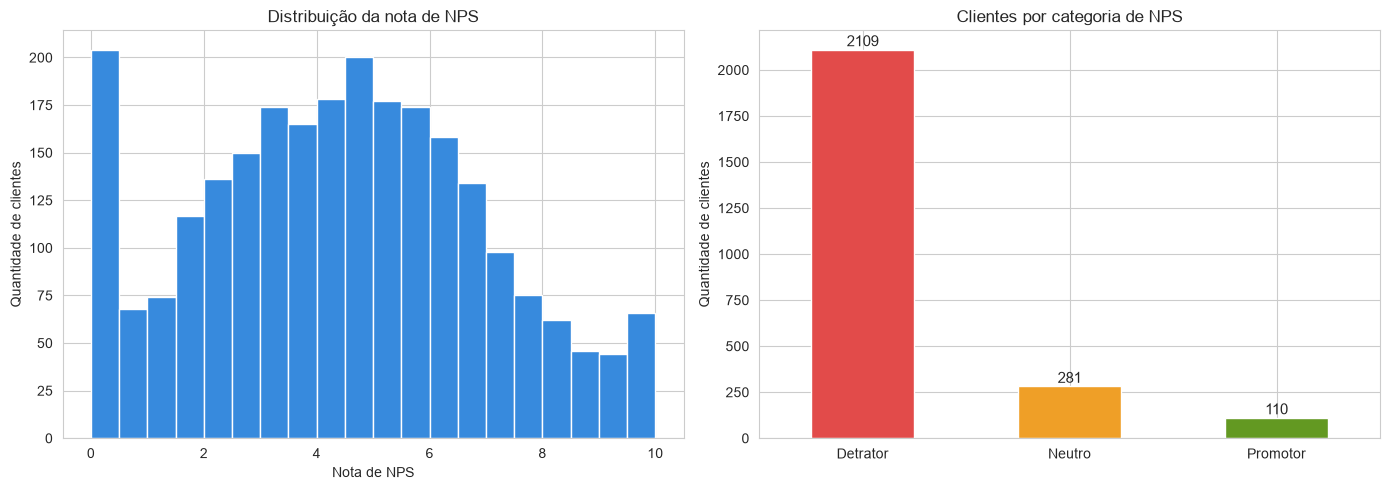

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma da nota contínua (0 a 10)
axes[0].hist(df['nps_score'], bins=20, color='#378ADD', edgecolor='white')
axes[0].set_title('Distribuição da nota de NPS')
axes[0].set_xlabel('Nota de NPS')
axes[0].set_ylabel('Quantidade de clientes')

# Contagem por categoria
ordem = ['Detrator', 'Neutro', 'Promotor']
contagem = df['nps_category'].value_counts()[ordem]
contagem.plot(kind='bar', ax=axes[1], color=['#E24B4A', '#EF9F27', '#639922'])
axes[1].set_title('Clientes por categoria de NPS')
axes[1].set_xlabel('')
axes[1].set_ylabel('Quantidade de clientes')
axes[1].tick_params(axis='x', rotation=0)

for i, valor in enumerate(contagem):
    axes[1].text(i, valor + 20, str(valor), ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('../reports/figures/01_distribuicao_nps.png', dpi=120, bbox_inches='tight')
plt.show()

### Matriz de correlação (heatmap)

Com este heatmap pude entender as correlações entre os indicadores. Três indicadores estão impactando fortemente na queda do NPS: `delivery_delay_days`, `complaints_count` e `customer_service_contacts`. Dos três, o atraso nas entregas não tem correlação com os outros dois, ele atua sozinho, evidenciando um problema de logística. Já os outros dois apresentam uma correlação altíssima entre si (0,75), o que significa que estão associados e provavelmente fazem parte do mesmo episódio de insatisfação. Vale uma investigação mais a fundo nesses três indicadores.

Existem dois indicadores com correlação positiva ao NPS: `repeat_purchase_30d` e `csat_internal_score`. Ambos, porém, são indicadores que não servem para antecipar a satisfação. A recompra não influencia o NPS e sim o contrário: o NPS influencia a recompra, já que um cliente satisfeito tem mais chance de comprar novamente. O `csat_internal_score`, por sua vez, é uma tentativa interna da empresa de medir a satisfação do cliente, mas mostra-se mal calibrado: dá forte peso ao tempo de resolução (-0,74), um fator de baixo impacto no NPS (-0,19), enquanto reage de forma mais fraca ao atraso, que é o que mais importa. Ou seja, é um termômetro que não reflete bem o que realmente move a satisfação do cliente.

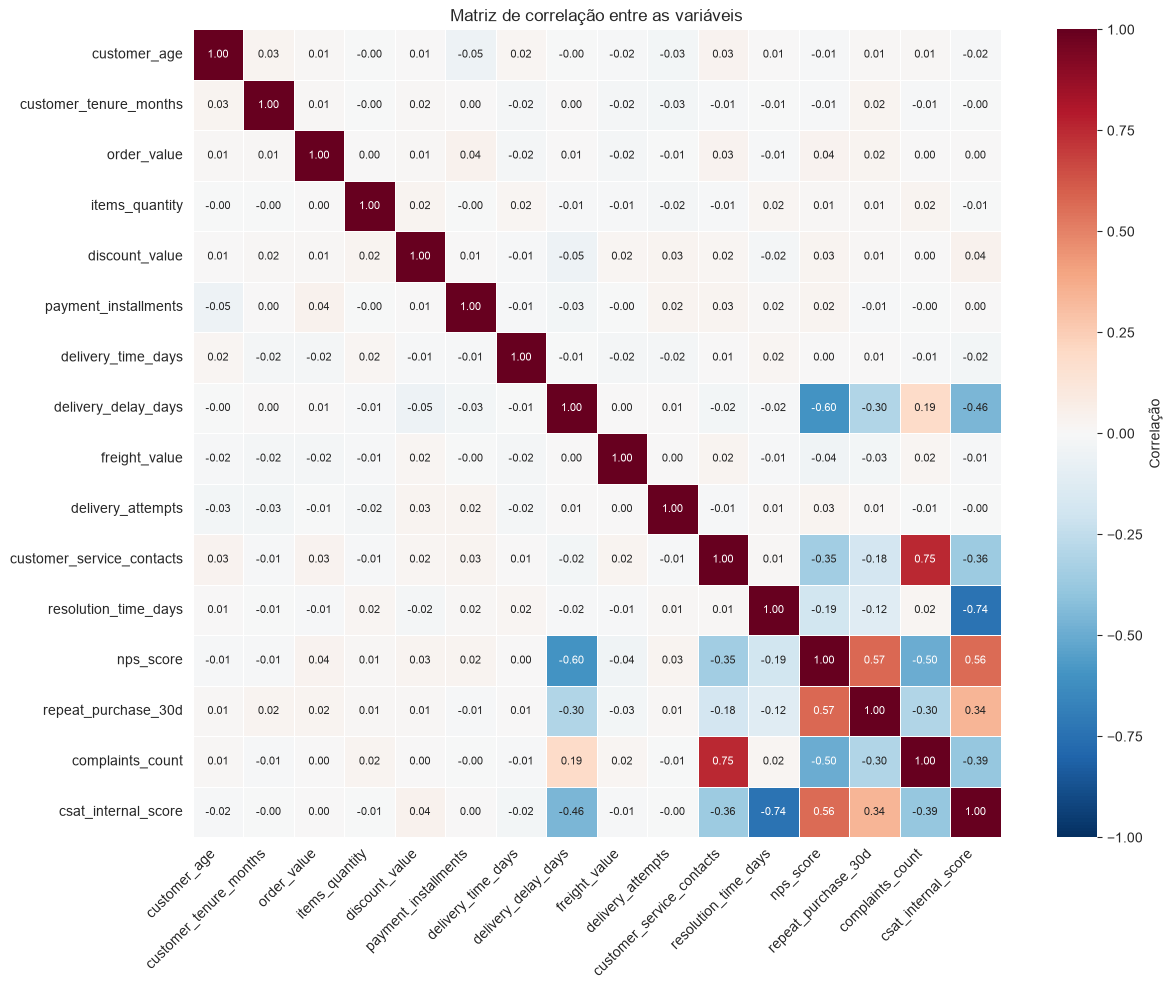

In [3]:
# Seleciona só as colunas numéricas e remove os IDs (que não fazem sentido correlacionar)
colunas_numericas = df.select_dtypes(include=[np.number]).drop(columns=['customer_id', 'order_id'])

# Calcula a matriz de correlação de todas contra todas
matriz_corr = colunas_numericas.corr()

# Desenha o heatmap
plt.figure(figsize=(13, 10))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            annot_kws={'size': 8}, cbar_kws={'label': 'Correlação'})
plt.title('Matriz de correlação entre as variáveis')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../reports/figures/04_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

### NPS médio por perfil do cliente

Aqui podemos visualizar que o NPS não tem relação com o perfil do cliente: o tempo de casa, a idade e a região trazem resultados equilibrados. Ou seja, a condição atual do cliente não interfere no NPS, o que interfere é como a empresa operae vamos analisar mais a fundo neste sentido.

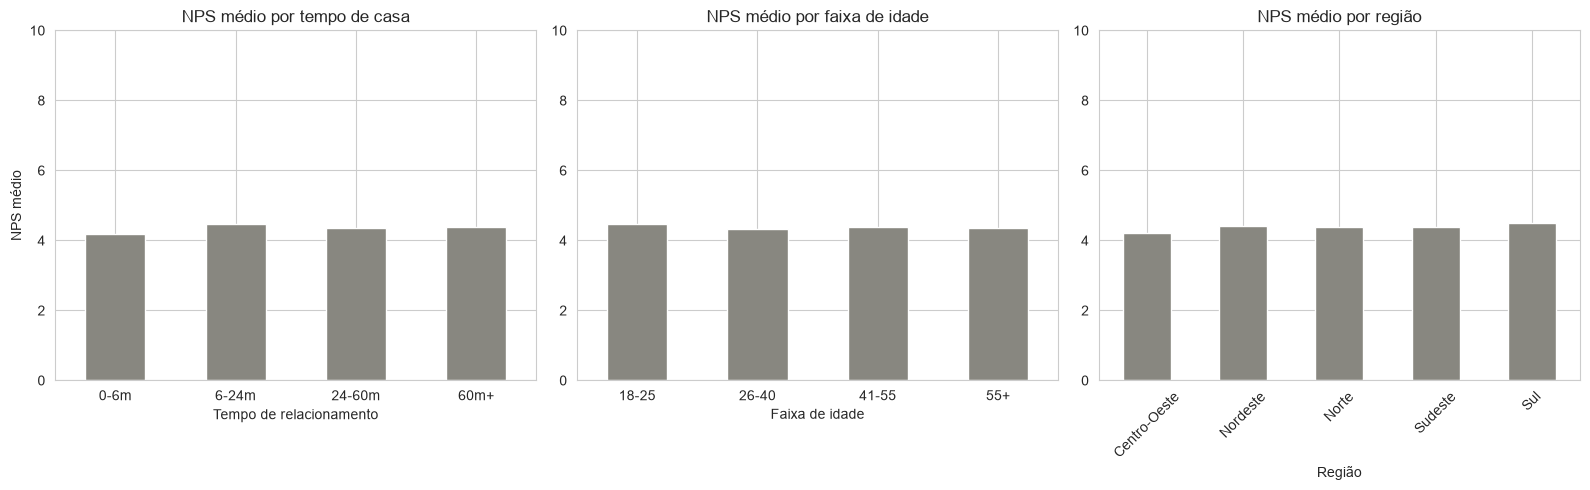

In [4]:
# Cria 3 gráficos lado a lado, um para cada variável de perfil
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Gráfico 1: NPS médio por faixa de tempo de casa (tenure) ---
faixas_tenure = pd.cut(df['customer_tenure_months'],
                       bins=[0, 6, 24, 60, 200],
                       labels=['0-6m', '6-24m', '24-60m', '60m+'])
df.groupby(faixas_tenure, observed=True)['nps_score'].mean().plot(
    kind='bar', ax=axes[0], color='#888780', edgecolor='white')
axes[0].set_title('NPS médio por tempo de casa')
axes[0].set_xlabel('Tempo de relacionamento')
axes[0].set_ylabel('NPS médio')
axes[0].set_ylim(0, 10)
axes[0].tick_params(axis='x', rotation=0)

# --- Gráfico 2: NPS médio por faixa de idade ---
faixas_idade = pd.cut(df['customer_age'],
                      bins=[0, 25, 40, 55, 100],
                      labels=['18-25', '26-40', '41-55', '55+'])
df.groupby(faixas_idade, observed=True)['nps_score'].mean().plot(
    kind='bar', ax=axes[1], color='#888780', edgecolor='white')
axes[1].set_title('NPS médio por faixa de idade')
axes[1].set_xlabel('Faixa de idade')
axes[1].set_ylabel('')
axes[1].set_ylim(0, 10)
axes[1].tick_params(axis='x', rotation=0)

# --- Gráfico 3: NPS médio por região ---
df.groupby('customer_region')['nps_score'].mean().plot(
    kind='bar', ax=axes[2], color='#888780', edgecolor='white')
axes[2].set_title('NPS médio por região')
axes[2].set_xlabel('Região')
axes[2].set_ylabel('')
axes[2].set_ylim(0, 10)
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../reports/figures/05_nps_por_perfil.png', dpi=120, bbox_inches='tight')
plt.show()

### NPS médio por faixa de atraso na entrega

Analisando o NPS por tempo de entrega, notamos que o tempo que demora para o produto do cliente chegar não influencia na satisfação do cliente e isso da oportunidade de manobra com relação a um dos maiores problemas de queda na nota que é o atraso na entrega.

Analisando o NPS por atraso na entrega, podemos observar o quanto o atraso influencia o NPS: com apenas 3 a 5 dias de atraso, o NPS já cai pela metade, e a partir do quinto dia a média nem passa de 1, o que é extremamente crítico.

Esse é o fator mais determinante da insatisfação. Vale destacar que não é a velocidade da entrega que importa, e sim o cumprimento do prazo prometido: o tempo total de entrega não tem relação com o NPS, mas o atraso em relação ao combinado é o que mais derruba a satisfação.

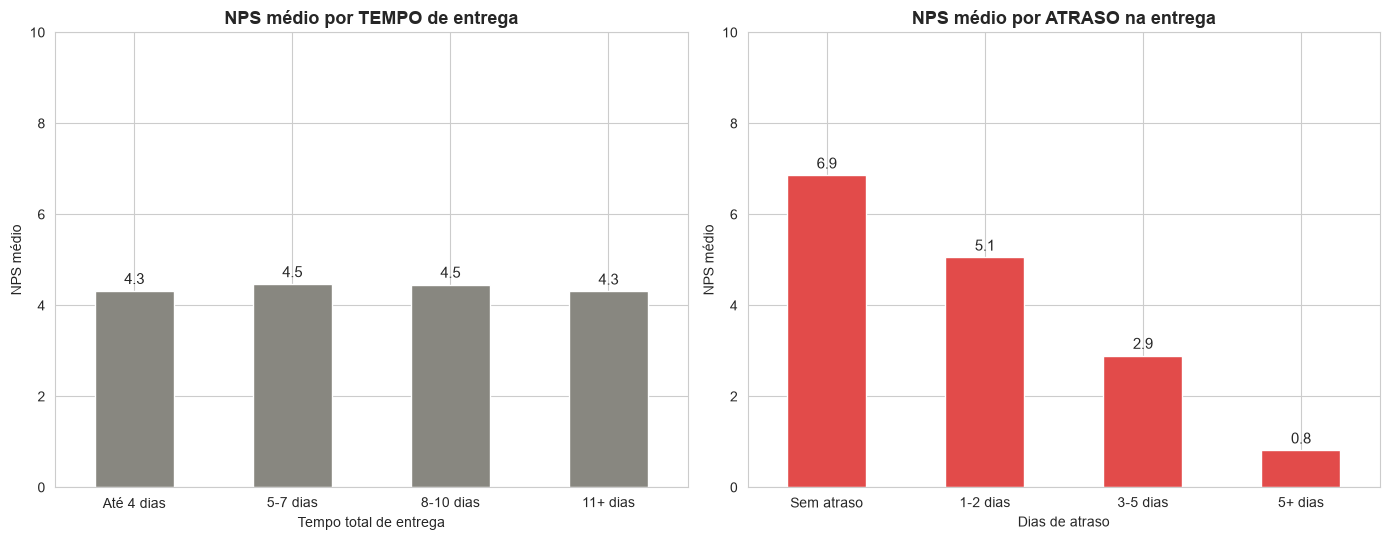

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- ESQUERDA: NPS por TEMPO total de entrega ---
faixas_tempo = pd.cut(df['delivery_time_days'], bins=[0, 4, 7, 10, 100],
                      labels=['Até 4 dias', '5-7 dias', '8-10 dias', '11+ dias'])
nps_tempo = df.groupby(faixas_tempo, observed=True)['nps_score'].mean()

nps_tempo.plot(kind='bar', ax=axes[0], color='#888780', edgecolor='white')
axes[0].set_title('NPS médio por TEMPO de entrega', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tempo total de entrega')
axes[0].set_ylabel('NPS médio')
axes[0].set_ylim(0, 10)
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(nps_tempo):
    axes[0].text(i, v + 0.15, f'{v:.1f}', ha='center', fontsize=11)

# --- DIREITA: NPS por ATRASO na entrega ---
faixas_atraso = pd.cut(df['delivery_delay_days'], bins=[-1, 0, 2, 5, 100],
                       labels=['Sem atraso', '1-2 dias', '3-5 dias', '5+ dias'])
nps_atraso = df.groupby(faixas_atraso, observed=True)['nps_score'].mean()

nps_atraso.plot(kind='bar', ax=axes[1], color='#E24B4A', edgecolor='white')
axes[1].set_title('NPS médio por ATRASO na entrega', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Dias de atraso')
axes[1].set_ylabel('NPS médio')
axes[1].set_ylim(0, 10)
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(nps_atraso):
    axes[1].text(i, v + 0.15, f'{v:.1f}', ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('../reports/figures/04b_tempo_vs_atraso.png', dpi=120, bbox_inches='tight')
plt.show()

### Distribuição do NPS por faixa de atraso (boxplot)

O boxplot confirma e aprofunda o que a média já mostrava: a mediana do NPS desce formando a mesma escada conforme o atraso aumenta, o que prova que o efeito é real e não fruto de poucos casos extremos, é a distribuição inteira que se desloca para baixo.

Observa-se também que, nas faixas de menor atraso, as notas são mais dispersas (há clientes mais e menos satisfeitos), enquanto na faixa de 5+ dias a caixa é bem mais compacta: a insatisfação se torna consistente, atingindo quase todos os clientes do grupo. Além disso, faixas distantes (como "sem atraso" e "3-5 dias") não se sobrepõem, evidenciando que o atraso separa de forma clara clientes satisfeitos de insatisfeitos.

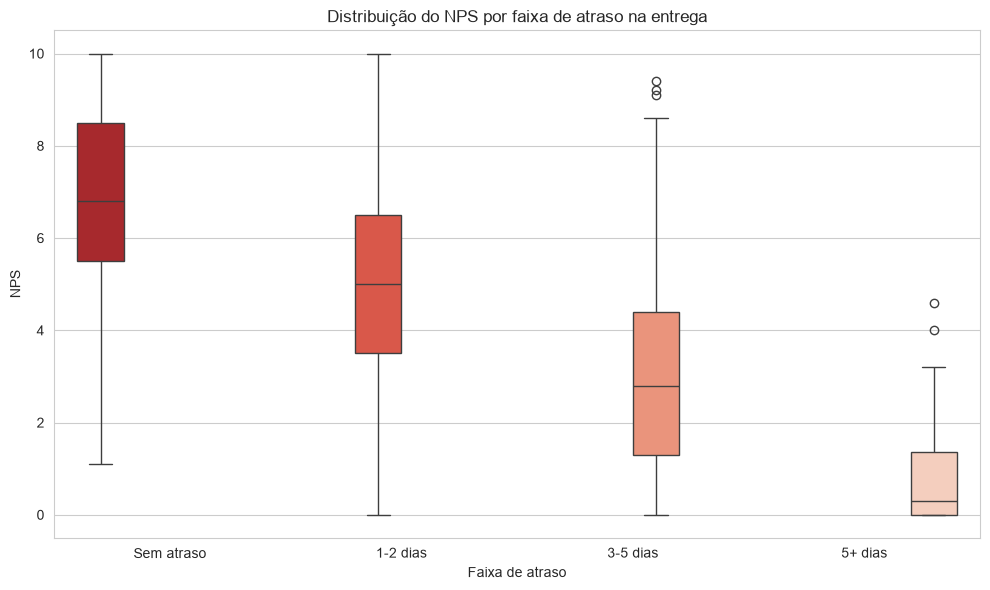

In [6]:
df['faixa_atraso'] = pd.cut(df['delivery_delay_days'],
                            bins=[-1, 0, 2, 5, 100],
                            labels=['Sem atraso', '1-2 dias', '3-5 dias', '5+ dias'])

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='faixa_atraso', y='nps_score',
            hue='faixa_atraso', palette='Reds_r', legend=False)
plt.title('Distribuição do NPS por faixa de atraso na entrega')
plt.xlabel('Faixa de atraso')
plt.ylabel('NPS')
plt.tight_layout()
plt.savefig('../reports/figures/06_boxplot_atraso.png', dpi=120, bbox_inches='tight')
plt.show()

### NPS médio por número de reclamações

Podemos observar que, conforme o número de reclamações aumenta, o NPS cai bastante. Apesar de a nota subir levemente nas faixas de 9 e 10 reclamações, a tendência de queda é clara. Esse aumento se deve ao baixo número de casos nessas faixas: enquanto há 63 clientes com 8 reclamações, há apenas 16 e 11 clientes com 9 e 10 reclamações, respectivamente. Com grupos tão pequenos, notas fora do padrão (outliers) têm peso desproporcional e distorcem a média.

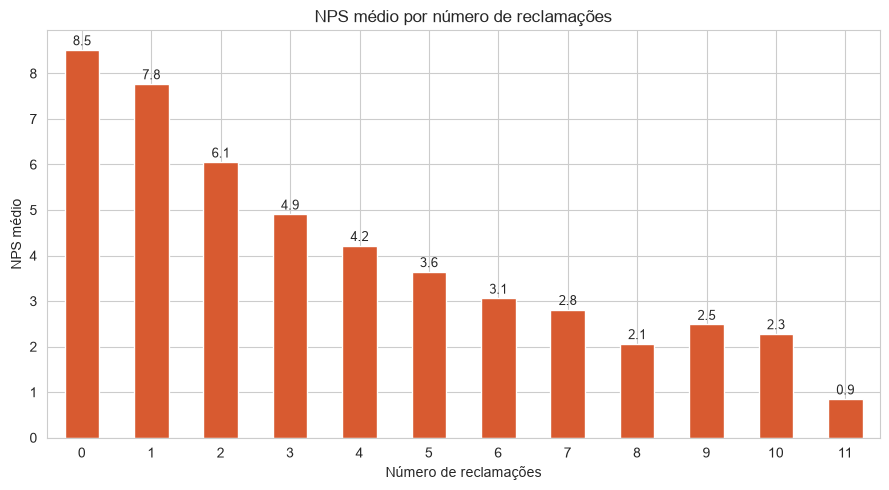

In [7]:
# Agrupa direto pelo número de reclamações e calcula o NPS médio de cada grupo
nps_por_reclamacao = df.groupby('complaints_count')['nps_score'].mean()

ax = nps_por_reclamacao.plot(kind='bar', color='#D85A30', edgecolor='white')
plt.title('NPS médio por número de reclamações')
plt.xlabel('Número de reclamações')
plt.ylabel('NPS médio')
plt.xticks(rotation=0)

# Rótulos em cima das barras
for i, valor in enumerate(nps_por_reclamacao):
    ax.text(i, valor + 0.1, f'{valor:.1f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/03_nps_por_reclamacao.png', dpi=120, bbox_inches='tight')
plt.show()

### Volume e distribuição do NPS por número de reclamações

O gráfico de contagem revela um dado preocupante sobre o volume: 1.551 dos 2.500 clientes (cerca de 62%) concentram-se nas faixas de 3 a 5 reclamações, evidenciando que reclamar não é exceção, e sim um comportamento frequente na base. Já as faixas mais altas (9, 10 e 11 reclamações) concentram pouquíssimos casos com 16, 11 e 2 clientes, respectivamente.

O boxplot, por sua vez, mostra a distribuição do NPS dentro de cada faixa e confirma a tendência de queda: a partir de duas reclamações já surgem casos de NPS inferiores a 2, com outliers atingindo 0. Esse é o ponto de ruptura do indicador que é a partir de duas reclamações, a satisfação despenca de forma consistente.

Vale destacar a leitura conjunta dos dois gráficos. O leve aumento da média observado nas faixas de 9 e 10 reclamações (visto no Bloco 5) não representa uma reversão da tendência, mas sim uma distorção causada pelo baixíssimo número de casos nesses grupos. Uma única nota fora do padrão (como um NPS de 9,1 na faixa de 10 reclamações) tem peso desproporcional quando o grupo tem apenas 11 pessoas. Inclusive, é justamente por se tratar de um grupo pequeno e disperso que o boxplot não classifica essa nota como outlier estatístico: em amostras reduzidas, os limites de detecção se ampliam e acabam acomodando valores que, no contexto do negócio, são claramente anômalos. Por isso, o cruzamento entre volume (contagem) e distribuição (boxplot) é essencial para uma leitura honesta dos dados.

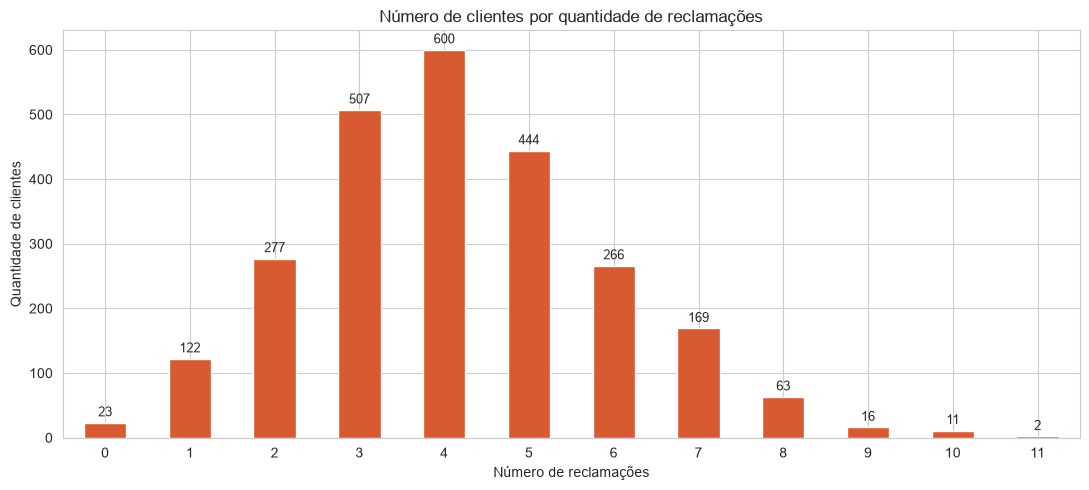

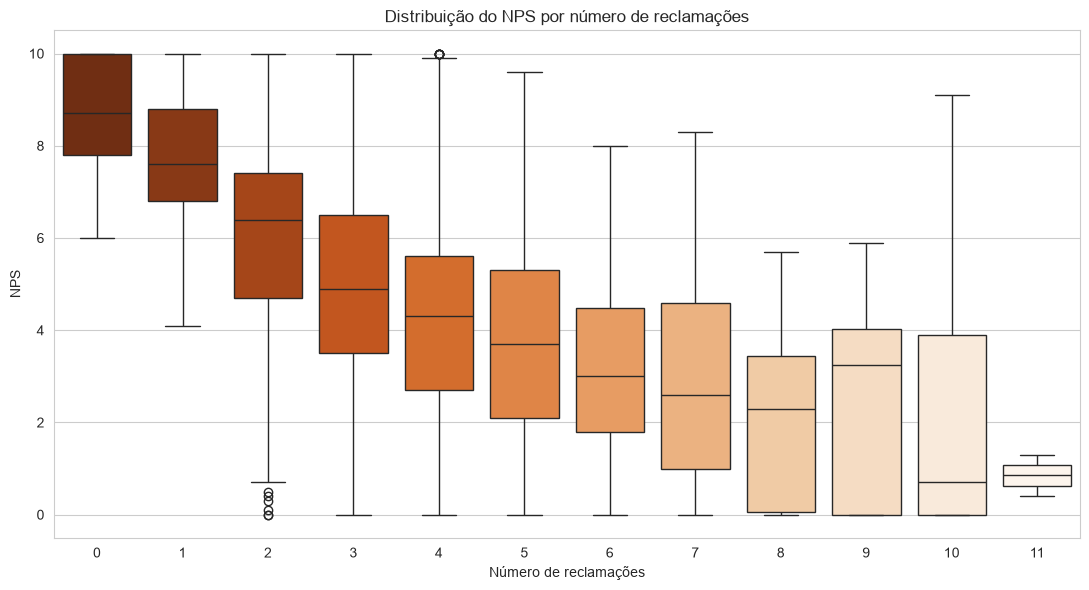

In [8]:
plt.figure(figsize=(11, 5))

# Conta quantos clientes há em cada número de reclamações
contagem_reclamacoes = df['complaints_count'].value_counts().sort_index()

ax = contagem_reclamacoes.plot(kind='bar', color='#D85A30', edgecolor='white')
plt.title('Número de clientes por quantidade de reclamações')
plt.xlabel('Número de reclamações')
plt.ylabel('Quantidade de clientes')
plt.xticks(rotation=0)

# Rótulos em cima das barras (você já domina)
for i, valor in enumerate(contagem_reclamacoes):
    ax.text(i, valor + 10, str(valor), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/08_contagem_reclamacoes.png', dpi=120, bbox_inches='tight')
plt.show()

plt.figure(figsize=(11, 6))
sns.boxplot(data=df, x='complaints_count', y='nps_score',
            hue='complaints_count', palette='Oranges_r', legend=False)
plt.title('Distribuição do NPS por número de reclamações')
plt.xlabel('Número de reclamações')
plt.ylabel('NPS')
plt.tight_layout()
plt.savefig('../reports/figures/07_boxplot_reclamacoes.png', dpi=120, bbox_inches='tight')
plt.show()

### NPS e volume por número de contatos com o atendimento

Como podemos observar, quanto maior o número de contatos com o atendimento, menor o NPS. A maior parte dos casos se concentra entre 0, 1 e 2 contatos, totalizando 2.010 dos 2.500 clientes (80%). Outros 18% concentram-se em 3 e 4 contatos com 446 casos (18%), restando apenas 2% nas faixas de 5 contatos ou mais.

O comportamento é semelhante ao observado nos blocos de reclamações: há um leve aumento na média da faixa de 7 contatos, mas trata-se de uma distorção, já que existem apenas 3 clientes nesse grupo. Esse paralelo com as reclamações reforça o que o heatmap já indicava, contatos e reclamações caminham juntos (correlação de 0,75), sugerindo que são duas manifestações do mesmo episódio de insatisfação.

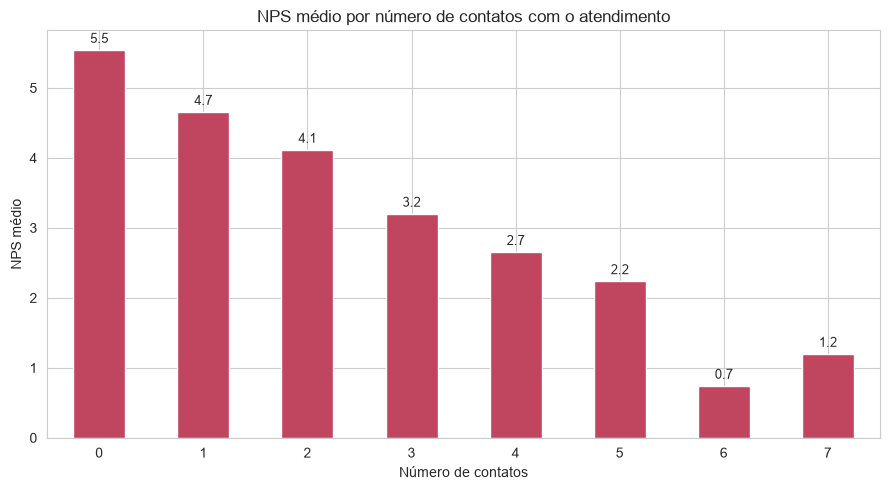

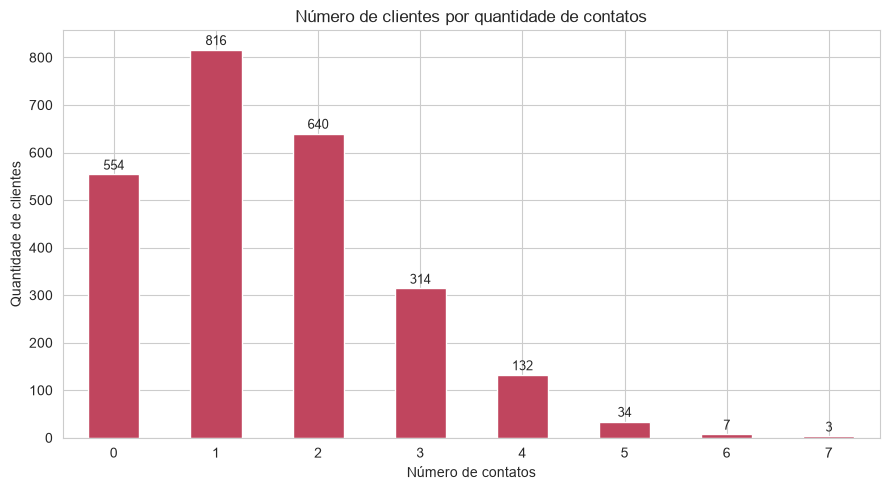

In [9]:
# Agrupa pelo número de contatos e calcula o NPS médio
nps_por_contato = df.groupby('customer_service_contacts')['nps_score'].mean()

ax = nps_por_contato.plot(kind='bar', color='#C0455E', edgecolor='white')
plt.title('NPS médio por número de contatos com o atendimento')
plt.xlabel('Número de contatos')
plt.ylabel('NPS médio')
plt.xticks(rotation=0)

for i, valor in enumerate(nps_por_contato):
    ax.text(i, valor + 0.1, f'{valor:.1f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/09_nps_por_contato.png', dpi=120, bbox_inches='tight')
plt.show()

contagem_contatos = df['customer_service_contacts'].value_counts().sort_index()

ax = contagem_contatos.plot(kind='bar', color='#C0455E', edgecolor='white')
plt.title('Número de clientes por quantidade de contatos')
plt.xlabel('Número de contatos')
plt.ylabel('Quantidade de clientes')
plt.xticks(rotation=0)

for i, valor in enumerate(contagem_contatos):
    ax.text(i, valor + 10, str(valor), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/10_contagem_contatos.png', dpi=120, bbox_inches='tight')
plt.show()

### Distribuição do NPS por número de contatos (boxplot)

O boxplot mostra a queda do NPS em escada conforme os contatos aumentam. No entanto, é possível notar que, desde 0 contatos, já existem notas 0 em todas as faixas, reflexo de este ser o vilão com a menor correlação dos três, o que faz com que reste mais variação não explicada em todos os grupos.

A partir de 3 contatos, as caixas se descolam do topo (nota 10), restando apenas um outlier nessa faixa; daí em diante, a tendência é de queda. Vale observar que, em 6 contatos, mesmo com um outlier de nota 4,7, a média não sobe, enquanto em 7 contatos uma nota de 3,2 — não classificada como outlier devido ao número reduzido de casos, puxa a média para cima. Isso reforça a necessidade de ler as faixas pequenas com cautela.

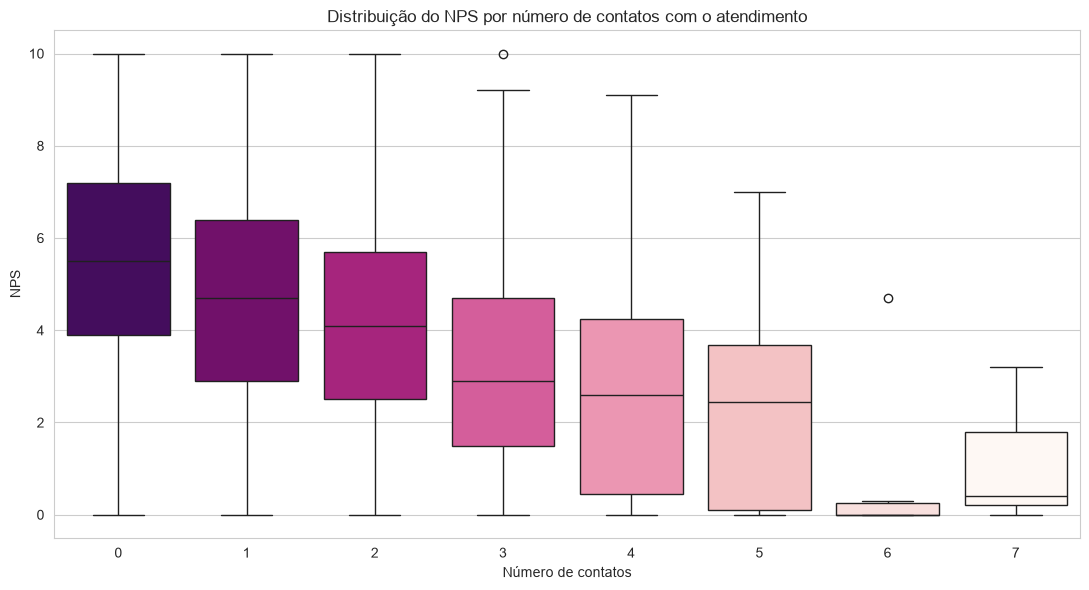

In [10]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=df, x='customer_service_contacts', y='nps_score',
            hue='customer_service_contacts', palette='RdPu_r', legend=False)
plt.title('Distribuição do NPS por número de contatos com o atendimento')
plt.xlabel('Número de contatos')
plt.ylabel('NPS')
plt.tight_layout()
plt.savefig('../reports/figures/11_boxplot_contatos.png', dpi=120, bbox_inches='tight')
plt.show()

### Taxa de recompra por categoria de NPS

Aqui analisamos a relação entre as categorias de NPS e a recompra em 30 dias, e encontramos uma informação muito importante: nenhum detrator realizou recompra em 30 dias, enquanto 38,4% dos neutros recompraram e 100% dos promotores voltaram a comprar. Essa diferença evidencia o peso direto da satisfação sobre a retenção.

Isso revela que a crise de retenção de clientes da empresa está totalmente ligada ao NPS. Com uma base composta por mais de 80% de detratores, justamente o grupo que não recompra, a empresa está deixando de reter a maior parte de seus clientes. Os extremos chamam atenção: detratores e promotores têm comportamento completamente oposto (0% e 100%), refletindo a natureza sintética da base; em um cenário real, haveria mais variação.

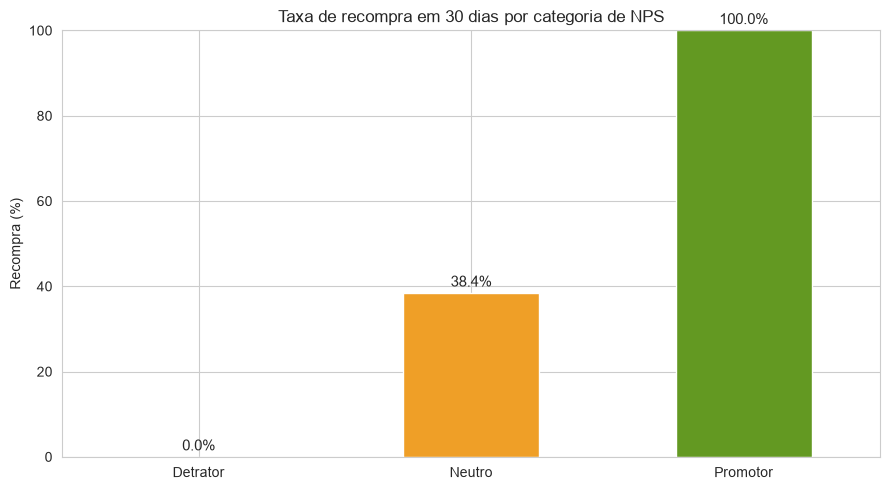

In [11]:
# Taxa de recompra (média do repeat_purchase_30d) dentro de cada categoria de NPS
ordem = ['Detrator', 'Neutro', 'Promotor']
recompra_por_categoria = df.groupby('nps_category')['repeat_purchase_30d'].mean()[ordem] * 100

ax = recompra_por_categoria.plot(kind='bar',
        color=['#E24B4A', '#EF9F27', '#639922'], edgecolor='white')
plt.title('Taxa de recompra em 30 dias por categoria de NPS')
plt.xlabel('')
plt.ylabel('Recompra (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)

for i, valor in enumerate(recompra_por_categoria):
    ax.text(i, valor + 1.5, f'{valor:.1f}%', ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('../reports/figures/12_recompra_por_nps.png', dpi=120, bbox_inches='tight')
plt.show()

### Prevalência do atraso na entrega

Nesta análise final, podemos ver que 89% dos pedidos são entregues com algum atraso e apenas 11% chegam dentro do prazo prometido. No entanto, conforme mostrado anteriormente, o ponto de ruptura para a queda do NPS está a partir do terceiro dia de atraso.

Cruzando essas duas informações, surge uma oportunidade de alto impacto e custo praticamente zero: com um recálculo simples do prazo prometido, adicionando apenas 2 dias, cerca de 62% dos pedidos que hoje constam como atrasados passariam a ser entregues dentro do prazo. Como já identificamos que o que afeta o NPS não é o tempo total de entrega, mas sim os dias de atraso em relação ao combinado, essa pequena mudança na promessa de prazo elevaria o NPS geral da empresa de forma expressiva, sem nenhum investimento adicional em logística.

É importante destacar que esse ajuste tem um limite: prazos prometidos longos demais podem reduzir a conversão de vendas, pois um prazo de entrega muito alto desestimula a compra. A recomendação, portanto, não é simplesmente "prometer mais", mas calibrar o prazo prometido com base nos dados reais de entrega, equilibrando o cumprimento da promessa com a atratividade comercial.

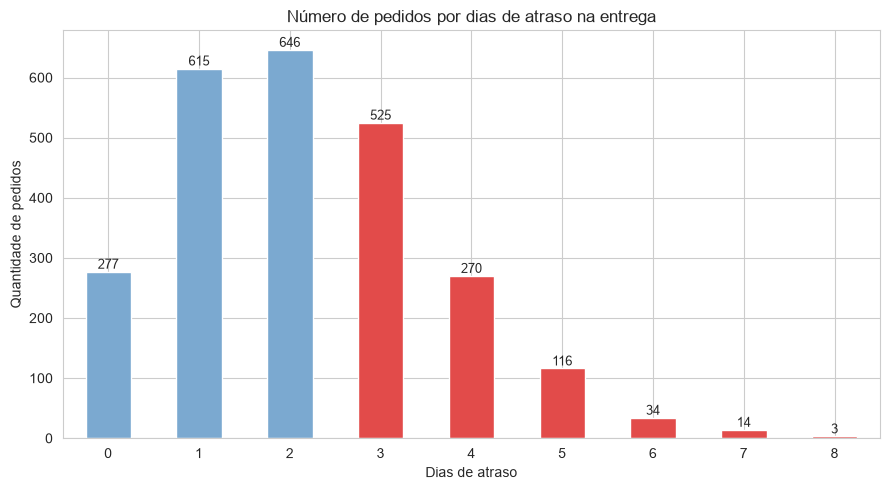

In [12]:
# Conta quantos pedidos há em cada nível de atraso
contagem_atraso = df['delivery_delay_days'].value_counts().sort_index()

# Define a cor: cinza-azulado até 2 dias, vermelho a partir de 3 (zona de detração)
cores = ['#7BA9D0' if dias < 3 else '#E24B4A' for dias in contagem_atraso.index]

ax = contagem_atraso.plot(kind='bar', color=cores, edgecolor='white')
plt.title('Número de pedidos por dias de atraso na entrega')
plt.xlabel('Dias de atraso')
plt.ylabel('Quantidade de pedidos')
plt.xticks(rotation=0)

for i, valor in enumerate(contagem_atraso):
    ax.text(i, valor + 5, str(valor), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/13_distribuicao_atraso.png', dpi=120, bbox_inches='tight')
plt.show()